# Challenge 1 · Dividir un circuito y reconstruir un observable

**Qiskit Fall Fest 2026 — Estimation Challenge.** Resolví los ocho ejercicios trabajando con un circuito de cuatro qubits y un observable $Z_1Z_2$. La idea del reto es dividir un circuito que supera el límite de dos qubits por experimento y reconstruir su resultado a partir de experimentos más pequeños.

Utilicé dos fragmentos, seis recetas de descomposición y doce configuraciones experimentales. Las soluciones incluyen código comentado, pruebas y resultados de ejecución en Google Colab.

**Alcance:** este ejemplo pequeño permite comprobar resultados mediante simulación clásica. El ejercicio muestra cómo funciona la reconstrucción y cómo se distribuyen las mediciones, pero no demuestra una ventaja cuántica.

**Estado:** las comprobaciones de cálculo de los ejercicios 1 a 6 finalizaron correctamente; el 7 contiene respuestas razonadas y el 8 incluye el estudio comparativo ejecutado. Las pruebas automáticas no califican por sí solas la calidad de las explicaciones escritas.

## Cómo ejecutar este cuaderno en Google Colab

Preparé esta versión como un solo archivo `.ipynb`. Incluye los archivos auxiliares que necesita el reto y los prepara al ejecutar las celdas iniciales, así que no hace falta instalar Visual Studio Code ni descomprimir manualmente el ZIP.

1. Abrir [Google Colab](https://colab.research.google.com/) y seleccionar **Archivo → Subir cuaderno**.
2. Ejecutar la celda de instalación de bibliotecas; requiere conexión a Internet.
3. Ejecutar la celda que prepara los archivos auxiliares y luego la celda de importaciones.
4. Continuar con las celdas en orden. Las funciones `student_...` contienen mis implementaciones.
5. Guardar una copia en Drive o descargar el archivo `.ipynb` con las salidas.

Las versiones de bibliotecas utilizadas en esta ejecución aparecen al inicio del cuaderno. Si Colab utiliza otra versión de Python, podría ser necesario revisar la compatibilidad.

In [5]:
# Ejecutar UNA vez al iniciar una sesión nueva de Colab.
# Instalo Qiskit, su simulador y la extensión para cortar circuitos.
%pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-addon-cutting==0.10.0" "pylatexenc==2.11"
print("Instalación terminada. Ejecuta la siguiente celda.")


Instalación terminada. Ejecuta la siguiente celda.


In [6]:
# Esta celda recupera internamente los archivos de apoyo del ZIP original.
# No hace falta bajar ni abrir el ZIP en la tablet.
import io
import base64
import zipfile
from pathlib import Path

_paquete_auxiliar = "UEsDBBQAAAAIAIm5cl1pUoSecQgAAB0VAAARAAAAcGxhbm5lci1wcm9tcHQubWTFWM2OG8UW3vspSsqCxLLbnsAVSliFIUEIIhIGFJFRZFV3l+3C3V099WOP74p3YMWTsOdReBK+c6qquydEiMDVZTEznu6qOn/f951TvideGXsojTmIC/HrL+IyeCG7WlhVmc55Gyo/m327107sgq6VkFVl2l52Wjlxvb7YVMFvsH4zWV/o/tyVb+7/2dsHhfh2r8QJR1rx6uXlpaj2smlUt4MJd3DCK9nitxF9IztxE2TnQysqbaugvVC3Ckdr04nQ0Ql7aeuTtIpdd7LtG93tRKNb7V0xjdD5UJPrplMCLlVWeSV2Er+qFDi9MaVT9ijLRglnxNkEUcEJdQtfdCc8HJ8ERF7EjDkTbKWEt7JWZrt1olRbA6daeSB3SmskOVvhlNYVs9m9e+LKS+uRBr+feDmb/ZPMCtSKXDRdcxanfCj7jTe9rA5ypwrxpGnMSTxa//bjTxcP16LVXfBIDBwWSJpQerfnPNtKOzynCGvtquAcAi7EM8P7aalTPvQwMKQD6bXswvWLs98jPQydN/d7/m/1zdMnnz1/WrT1gwWt6oQNnahU0zjy0ljkKKIjW4dxd1IWTiCZuvOqIyuAy1mUQMehIIQq0RmvONYt+xaLvEVNljehBGgyeDjbqOc3r1/zaVbGIpbKnxTc8SdDP2nX1spdC4vA0RdeuD0djF8cH4rgqbKyrpcUpupwGGXR6Vv87DrFRNK9Qt61jVmEkeaIB/uz05VsCFbKajJBmaTzYOp7YO6km2YKNI7nNWBrrWokubxgOgbspLKpo7Jn8tAvYlw90D2yIXSVsh4A9ucFO8JERkZrDSNTTnGChti2OClD+A9Lt0o6TTyJPJSJ0cy8iPBXe+kj9NQtuYKyOg9qabdXLhauMZQHp9sQw4IWqAoa8DbJdpJARqWDEdrhkewjHELwESIclwTDjFP1Eklp84stQxJeuB4F2eoqw4HLKhvwHOkOsMYFpApLsdW3qGCu1JJSK8pQ75BWOgmqg9eyssa5ASeTeroI44w7bAH1HZ8F6HrCHWsMOd1bc0RUDihGIfEJ1RJmOyifrI/4AOYStyLQGtZGfBIwSLFK7CFmBovU9crrSEYiVUcq5JHXXHbtkNExYnHEI07+J4Tss6gN8Um40PcGCsXaJVoFAgPS4BzDdDZ7MvjQynPChaIKpJgjYEiIiOhEJ1IMhEBySznpIPGuJem3dzOHRkSue2vqUGWMRDK5RSZXZdQWtdS0JYK6Ry0YkAPuDWixV7KG5LFVbigt4kbOFem8Sop+E4BMHDqq/yeiVo1iGtCSElSrJTgWG8ZeoltFreWtrIt3hCiQcubuQsfA8XOHDR74ixF1BgK3GDoP2gGha3QB3QspHNmIdaCJ1yDSMi3mCvBLLDRIG/VpxnpW/ySQAAVqiQhZHY6wDsBVVpekWO+QiUSaO90Ou8nlcwSmxqLI/EgV1BFRxUyAVrVhQPuYuRirKLV0A5fp9EjmyNNCfKblrjOOMhRfwM+govaTP6wN5CiKh0S4JFCDJC3YYFxpjOO8cIqmcmTEQal+NruSqP6ZCEOsQKk5vFQ9yjWhNcv6oOXM2gkGAVJdRj1Mr+5KRqMgGTYW+V0s3I7WC/F0MmVATKHELKbcKuG4J92jQynVJ2L8gsUquUY+QWmpvryBYAmTCWGnqMVqap1rxN09F4t6XCG+c5EXEFiImrE7zHz/RRP+AKXuyIlQtpqHgbutn4kuj1I3DF9O+td9bNjwcqssSZsbBTmDdDZbiuuX2h0gC8SZZca8DxB4LZs39/fe9+7xanXDq4od+lQoC23SgyX6sOnyvlXe51aYl+jETXqz8QZzE8nKJunUhjNd7H3bPHiMXm2jdmbG3W1EBTn69BbqPbJmKkTv6yfSvfTG0V/yLMNto8jEJpvYTE1kT3lJrv2JZzYX2zeKpJFDhkqLJh2sisJKzl+mzNaKgACSMHY1YZAWMYHfN4pNC6FulEtvN/w2Z3x109erO9aGECZhca4n4xDNTCxJaOaiPDMcMzuLCVpokKsVR3zX8dg7C4wDoS50iU+mXdWmcivVrWSvk685wjwRNLq0kPkC536OQsBJKH3q00QwovwxDqFTN2ha5OkVPv9VJ3gyditsXeatMPdChkYLEEg1kZupgjXZSDeHS/xL6sROxYsHEZ0AT0yazy+HCxVGE4z3u8fzufjuFeb957Jm6tO967cff3Zi/jWXAAS96lEaQ5ZeWBTLz2mUrJpQ4wnjim8WVu9YA8beHw1TY8bA0Gis5oaZbzzj3Q7eksLBhOUJ6MD6qW59EZ1Oc0PCDblMnSunOFVokAa+knV/C6+TrStcRK7/TcmBeWbyckqGdGn6P2lJbBDX/74iAG80yyYETaV48fYQ+A5pjt8q5Esvz18JOmz98TCY5kqvi4t1sY7gyyAb2O0If198+ly8jCRmslwnWRib2f9ecWIxpqrwBzi8t6wMszzlldHOWkaWWG+WrDdTSrmYlq/GQXVySXubmk9AaF6zRNlxzntQSNkJcT7clEE3NaGUj9vwcRkcCDBwHxuiSCiQNSZfoaylscIY6CZ3jTRIpdBjp65VjOsZj/PDZOKUtNWewvrSuHBQ4rnGgC01G/hSaX72LPygNeg6vxxQxwPmUVsfcMz4vQH7hqY1jAg0imJoj29NT7ykHM/HBEl7q48FRq2VLN3q4tH6UbH++D8ffnR8mOn5QpHo0fBXLMT8KhUDz76iq0CGqUgqSt+AwLcrul6N78A43NHsn9n9qFivL9YP2W66mIoSWr2zPMfT6DblHX3VRvbtMrNrvL/Qxdi077zixUtJ2rIYv+3pufOA32gT+Vrn41n5W6yB4XQrwDWu55s4NahYcDc2w3QJ57OmR9HOcbJ/a7pIKPkdUEsDBBQAAAAIAIm5cl0RTVKcuAAAAEgBAAAfAAAAcHl0aG9uL3dxY2NfcGxhbm5lci9fX2luaXRfXy5weV2OywrCQAxF94X+Q8i6CH6AS0GhC3cuRIa0pho6nZSZ8fH5duwU1KzyuDf3IGKtLVngF7f3KOrgxnZkH6BTD0f1faPaw3qFiGVRFp3XAVbiQiTXcgAZRvURduQvT/J88NqJ5Qr2WbE42F3F8SLfLmkHSy6JO6YgjeV5rmWQGKoMNX0bP+sHWblQZJPGBGMMWWsMbOBUFjAV/nFgBbiQpP4ndz5+J2OV38wASZARUjtmzw9GspzL4g1QSwMEFAAAAAgAiblyXSylo0/zGAAAYFUAAB0AAABweXRob24vd3FjY19wbGFubmVyL2VuZ2luZS5web08a4/bRpLfDfg/9Opwe6RDMTPO7uJODoMNnOxtgDyc2PcABIHgSC2JMUVq+JiHJ/Pft6q6qx98aDSbw3k3tkg2q6ur613VnM1m74qsjIS8k+uulZHIyo2o5boqm7bu1q3IxFXVlRu5Eeu8Xnd5O4dxbV7u4JWjrPODLNv45YuXL37Om485jN9s5lUpvn73XSN2spR11krR7qXI1m2XFeLnd984bzY0Xw7wjxL+KtviXqz3cv3x5Yuqq11E8qqMxY+V2HZFMdeoiCY/dEWGz0TeiK4BLK/uabYjrAom/1ytq6oBxdls9vLFtq4OIk23XdvVMk1FfjhWNWBdllVLgBo9ZpO12brImkY2PMjcisQ2l8VGj2zvj0gOPejr8v7lC/37kLV7e9EVbX6sq7VsGhyfNeJwNE9bIIe5KLvD8R4HlEc9x7Uirn7+c5eVbXd4q6gQibbOyuaYF9IbHR+Bxnmb39gVvM8Ox0LWv8gGkPEHXyuYaV5uKx7+LuuK/Pu86Q2t6XUHmSb/BgbV+VWHFPQHG9xqfuFt1R0LoMAPmb+6NLNjvpb1e7W3VT0YFJdV3kge+iNe/FBtZBEJYKOqyOr8E4BPZV1XdSR+kdmm6tpv8aoHarOpypTZWYMLjlnd5riOFDbrqpCHyPAxj00dBo5evhBP/nH4mN5dK15Lb7Kik014Aq04A+4FPpIbvJNuQVRcZNXkeBcfA2P+dAROyj8R+HdZnR1kK2u4/428ydfyLWGR5YD3yUlhH4smrq4aWd9kQIN0V8OmORP/ZB69rYpCrgf73gN4fdzwqx9uq5+7q7wFRfCfsC79VpwDZlm5trz6nb4Rib9n9eY2q+W7utpaJo8bJGLT5mvzSlYU1Rr3qdlXSAzYwA2S/AZYQoFqUABwB4EEuIACNdfLFyTVMONWAi/DolAnBv+Nm0NsEy4UnUGDfC2QgK3cgZ4ipaEnAf1GOkfc5u0+L0kHIYKgkVqZrfdIu7WlfkzKCP/3V6NVAljWJ1kmH+pOhozT9yjCjZ7/kN2lQMkUUD80C1CbrUjE6z//xT51GNM8v/jTv9sB1Y2s9yARC7EtqgyfX17An/jCDrnK1h9/BQ1kIOAI9RhZsJFZvd7DP7CcTWPhvLZA8lLtQArIOCgZjPor58V+a4fq+ZSGW/Q0nnqIVCCQ6pIJ49wyorxQahnv3cp8t2812mZY3t6nh6z56LxMK2CU9cqKapevsyK9RgaGhwXw3xJGrGAImYRgI7egNEFQwdxV9X2CI0L1cl4CLvDycX/fEJQiuwfF9EwoIOu/C8Y45T8A4ZDpF0wRUPwLZHV17WiCdSW323yd0346RETyO880cTQpuysLAZ5s8rV+YpkjRc225qdL2K/ILmo1zTFo3lHXWeRZk6T5xlkCi61zayPXeUPcYW5pDeLf9ISKcLKMurK8yA+ZlvqRVkL8tAXjJ5dEOHeBejCpiKxHWtDhGa5ckwbwipCfp7cah9FWq1VuYQMOh6y+DxpZbEMx/6oHaGFtWC3BMSrpeeAQMsE3Y+dGZAiqHvHVhDlkUqvBfBU59FZP7PUEIGcvkkKWtKLYuRlOvGcEhsQ6AYIEMqbfYlvVAryJUpwLC5Qk+CYHR7Olt/mm3SfwIACwWmvF4MZpTXFqDqF3L7l4ar72tlLwUvBzhtPRzaDIDlebTID0InnyWCEQigT0bniOr9L787swRwKnSuOCA2Px3wGvqE2Yxoi35xVybzBcDGGWI2YOCUBKTizy2Tv96hWNZAHU6hMlijwxsG63Vf1R1gHIbam8oIiNViSIKUBQpNygqKMhdzyJD9VxXsgbWYjmmN2Cx5DVO9mKHfnrysiCT1FLiJluM4x5QDI+gtRVRwHhzv/A9NWt9iNIA9X3jhiDTTh2LSkI7RoGjJa/0nF/MUCcE4U4ugS7DPRHguFM3FzXbaAWE7sORXiWI+w7GIkDx9w8Dw5yUFpU5CwhpWu6+ltWNLKPycD1DRQbkXcCpkkTJqHtCh32sZsaNxCdBoGaTNGWB8q7NcgdGCL8BwNRCNvg3uIEGMISYsjZA4SOMoDRYZymJdA+TR8X4gFuPM5C194X9+PwgCcaGbhsqYN1Ys/gHE5ct3fAJodjDMwHBhzc4rs2mBFLzjQKEL1I4Ep8H4L1BF+J3+WA+QZt2Z2murF2GODyKHUVKN5OfKEB7V/vmiRAqE9IjQ8cPX9gQn0TX7eEGIpCvhXoputFxBAgFsy/Q3c2XPi8wzOifYeNaM0cxl5mGIr2IoftTEdt+RpdZpZmZBWJmZSHyfkXu8dGgOFdF90G1IAilKD1dsdw5kzuL1J5WWvENbLCz2uGf29cxJlnf/obhTdDlp1c2QyXo3aRkZN3OUY5GPfAxKSyMD0wCwWFaQB4sBca08U/T8ptBoEguHcPaq2PLmW0C6OeTAkRk8ZjHHfHf63yMsCsDMBJXMsJa+AxeZNmBUAJns023iyu/K6rAyZLWHTZa/Tjn1VknNyFiZPJrxsbzG6xor0BPCDYUvugcrOTKMA8RbzX8XdMT4xbSGpbKU12XlViB951cjwBvRUaJIavozm/9BScejnONhsb6ZDSDi6MTiKcTXbJECwSV8A+jXYxlrP60ywSs+YO/6a/1vQ3MKlsZ6spY8MoQFB4TPgCJMuxlikZ7+SLKRCowFKb/UrMupVmQ+dQcwHgeenzACl4eN3moorsShbGiPcDYrv3GK7+Jn6sSrmyrsZbbTFuIMxFgQTlgtsEIcFHzOtS4gjlV6gc7r81YlOtO/SM4HFVg7DjbnBA8ZbRE8isMBOlcWupRqoUbFHdyqaFvQYRnNPOUZL3LhbfbQpJ9rpR0PbZjRS0OsL6DSWIc5v0BV+ozYsCdwSWlmGWF3Fv9zKvhYJM0GIF7scKZCu/waSzzkTvZXHExGIjgItAacSGLCb6lxTjI/0C2K+dYSbHg2cTRDnmBDbX2B/cMrK2164WuN3DpmvYy+uV+EMirvtKwjxM+Le5tfKHXtsh16uB4F5rJYf+sCUc+rmuX+yaRBVqA9AljyA/EQXsOoxppwjcNQJxYGoH3EEB6RF3xw3qOA02HOh7CPY08wcusOqIWVXymXtJwZDLApQR8Gnh4EWPl5eL1WIog5pcemdW2hVmHJcXK40mZTaRFA+PlowEv6lqYPIAV+jurHoBpLjV4U+g54hAg4ZxdsRKBlzqjBHJLVKaZBKimSFv2XlpdKSmoMgGBlHmOdDI6MlV3jiAKT/K+wRMTOhiaFZAo3u0UQgprqPfnj5VT60uwpRmMLQ1kZ9OAVAz8Kvy9f0s6qdQ8JmTF5q56vIVO3gLnefUqgvewX9Iq41leEB235ms6za/A5G0sypNVlawpC2oI8B2XtXZusAKFNlckxgBtbEGVcrmbZ7h38akaM6s5a8wqlFu6Tw33onSbVqZoI+CUdZCcBXMOC1oh+aO15S1whq+4JDdYzAKMyDGqInD2OSrQEy6WiX+F3qZ6KDnu67qGnGF8WAjqi2BrEDbvlb6EJS5STmDLZRguqQGqjZpgXUz8NzFHogM7/GghSYJiq3CbwvQ3ogKlG19i84Zr9OxBWZn3S3osGr2m835CYcDQARQxTt3fhOgCPqptlh82IPOhv/zFu9lV1O+PyKlkpXKHEN8rFNsc1gMXLfA/nVXyL6iv5I7eCehUlsM02xTsikQvYd+4hCCsSPQM8WEbZryU8WpZCfoB8yimDawvo2pDZDWK8XDTFEUPQ6mHbkj3ubiHS0+j65bRv6wrUIEs678WFa3pZlmZmd2iG/mltddVpDL48jf6RkcMIcOWUMKgoKrdaGMuHMjWa+vxOWF0Fap5/LhowEm/WCD4h6QmXUGGpodPDIN7BVqPgUJgJnUrDMTFxbKS0lEwNvwFMJfJmO4gkaUzv6F3k4nVvepgfzEMoVBBIYyIsq+nSLdEJEn6aXFl6vjKt5sOH/oCJciG1OKxycDjJ7MPz/MeHWpYcqFWfHjOA0MJV2fn8N/rSaTqVTGkCzOPS9pYIHzApY2mNSpiBk7BqyAvLJRaqz3GT4554OK/nJ7wu4smlQ4Zl8gCHw9trTwJFLLa/H55xqIsfmTDixHd8Cji9NgL065KfYFCI2QA2B5Ab0bLhAjQmTUhelPRXKkxiXaF1lNxFLGN3L8MnTBhyDn4gFdh8fw0VYsWaXR4lauswx+btT3mS3CXlbZoZkW0f8D7xnV0fN9YwA9kjfHDLmXH0cVgzcf+lRC58/gp155DFEj99MYVZ3vMHMyohmIKEta68oi67/u0Z4dY1NZ0itNCUai9wK9pYSnjTElGp1bs1ALSdgFOppkdqKqbcExpFUTV5opaFiz4vCONQWHNB63J95V5K8v8a4mKzlH7KJIlcFIZtpbHE0rUAJBuXwmeNcuqir6ziYmaSsAX+3uk2EChx89VSSjlE3yjASQSYYfx2qkjtyNFkqd52dWS503uGSKVXruQOCiBIMhAN5LXau8v14R36iHOtvZwt7UIOAmXE+qmTfQ4Vud3eqiV+grFEM46xnH5Irn2/sghN1JKQfhBXMKEFopYmILO8bSkB9rZ1dNwBN/KS7l/PJPPYmm+KHspPcaalKlwVFxPMy+85xEj8afJRqhp8Dq3imVt/D7qawt7yumpH/jTOF3mgsS07MWLJVJcSs6ajdxC5vuql+fhVu4XRrL2FaGbLztq26svyqIbin0Kddt2n1TMTiIvCHDwIXz/Da366VR7hI6E1ilQzEKsG6KLLFGnC5ojWtcISVIY3LnG6UT6Y67eAwJXQ+KBcrwoZ3lKjYPCdQQjM+kZvRXYqSMiMatvyZvoO1/Oqt6gJE3aCUI6ZGcbVWB8qx3EOo+9GZ5pKiUbkQWxwfTLxV/sfOqDLASNK6k8ULx2QDpV/RYsUfoL8HtJzmHL461nOsWRMUT/PpcJUUhPDK1JRdFmxJ3G3NgC0/1MwaDQkVfGiL3piN6KqdNHXYgh+URPKFtOJZ05Ewb61DD7pHVu26LsE1kNnHeykMzqLfozRh7O8TUKz50aRCOJAwV7X8BgsKLOhzGVHMh56RTAE2MBal7E9PipXQDKkwxMwOpCJUXNeuVfjgDaQa4JsUqVO6qhIdjzZbB+B44UHvTOi1c2OiGBVoDLFZpRXD8Y+r8QlcWB+GdkeQrcLq2eDC5QwPP1o3uxQjZh+RgT9GKVzia3uWePdue18e0ljswBJj8L31U4zU8ahbj1oW0WN7yGlXtwlkZQw0X09YJGJKHkRdLgSAS7gCSDaEgkWM24cn7ncN9KO5GesCQ6/q7/EcRXIovv7TrCU9h3Sfsb4mgt33amWAH/tPhzhAkbRzvpHUFAw9U5LlPlq/Ob1NyVId1fjB6dYR9aQCvMO0fuUscYy1CfTm/XMV+uyeXiLwoALMh9k7oSh1ZAyYB+7rsIypMfc08rVi5shL2kvxWEl31Fom053ie0n3scTOmo0SMxFL5QA4xCQV11ynHWF8pHPEfzCymbcgxV8YndzXApCvRc9FjedfiO9rimsyTY6TPMMITBrhq2mdbYL9BQ/WyJb0W9WB5GV/00rco4ypzq/KJMtYbYrrXaDmrp6XEpsVUOzyvfqI9229oslnhYXvIKJVQELCVqd/3oTsaNiqLprobliaPMFiVwTq0QZarMRhcaqIItQUA4VN+VFttR0WK8C7Pu1aAQTj3eKMm5rFwVBA+MjJWT0ZnnOgBxxy1+mVGkIzpx8E2L0CbpECWvCiyho8I9F0gBYu4xilmawlgFHylFoZhOIrpaJ+5g6d6/v+OZT9Bw72xqJZYp1BjrNE4Nja7nOpR3GlfuKE3rR46o8OV8expo8RJUvYehZMtynhkDb1x3QuWjBSqxFyVsU7121pdkoKoY3U40ArAWc1waHZHqx8MDf1mearndqqUMk0tXTNRBYm0qnVrev4J9KNO0XCTmlfgtSmS0V7zSIy1jp/WhFoj6MiOrV1kchqRcNp78QUwYDnyVuoVv03fp1cv5yYzrpePv+sWziUvl4Ys/OVTxRvz14tzKpKwAz40l2gY9owR82T5j04wgX9SlbsGgmWRiU2+pSp6a4A5tb/RLvoeSl4o9lXPJj1teREhToLQmap9hi1GrJfmCEZcdZudNEVJ32KcRmlxqlelbxXQNrWUfh/Yiy/F67NCeQla6V5ov33jolnSErMWHJaMavl4Qm2HzZ84QS/zMLRhz6gdnmjuZFPdryAO0k6Aw4MfmvTjrREUKeh6xBLNZBATjURJj6O4+3VxE5Y7bxp0POqh2rgFY81djg+UYqYmRZULw19cuDkz+93LZ/QLSkNK9PqxnFL6oP6jqGtq+ifbGeGHXj/+vMrqOpf1gH4nuNOyI2Z0M0BItVmw4wvqrsk36jw3NuxjPzjlDmfhc1aDLi7gPYIXET8Rek+GhHtWoW0ktkPZwSk0PT1mmAiMnxCVt/8rbvKqwG5TQxK3ZDNzOzvp4HJ6wMPKGNjgadZF/3ir7oBfKGVD9oAPOPMxUPxNPVL8IHBUH3db6kqw4lA3EgG1iTS+FJ+Ji/gS4jx6o9/gjKjEYIn0iR06TN2jEOFBTbp8eJxGBcNT2MEEQDzcg+hE4vLM8yNiaZgfYoUlwVqFo8jX6uD3KOpq9mR8LGM1tVpvcOCeLw+Wy8u5PndO/yCO+lo/WGEGwscbdy2LTOacEFK6ZrB5zvLsaaqxBQ53Ocjg51X4u7ewN6/dwtchq6Mlrmble0o0k3va+j3Yte9xmbXt6nt/AIkU6NcV1miLXQcSopu+BDjHHaZv1GcpMrCmSD7wP+uuUT3JG2lPRZHUsduEZ7ki7Swo8XLFAg96qWeRutCtvnzvojcW1BKoVy4NYlmbE7l2alTL9Y3UM5PCookj53SxJ+/+VhvfAn0Oi9Nn+sFXLtLnuR+GprdVV2y0fRcjTpRZppoxUVOOk8Ar7VulzTV9feJSeVDqoKQpGrNm1J8feb7HHGETKVbK7XH313+JBtXJLVgtAsun1S/i//jz9ElY4B81C+b4IXIp1EdFOHnj9J/Rst6IdV01zZy+XMItoL1vl5zfhjgVf/h04C43/koGQHQ/mhFAULOvNskM1t2obCfsFQqnY4MSzyANHJ7RjqSn1DSOxKaKopBF2u5RVzbJZeTfd0/xXnJ/JekCWIZVDIEfLXC72j4vNmlDjmkiymMMhm5THeL3cOe9vO5wo+kAYxjTMTadWpiMSkxmISuBQflbERjOOh81Ub1Dkf5v0EMUuCkqOvnRaEx6mViVo5rCJXIX56XqFXViVih62mGEcjIycGXbfDmHJqMOnzbwMI9NmZA+ZBHAJm7wwCKW9joY/cXr0LbRK51zi0cjmAXjuiuDsWybUggD3E8zlkKNYSc9/EP9UZpgePgAsIpPHTjzKn7bmRUoxxs2x80IGFCja7xisEqA4Ik7eK4OUuINc1rJFuDU6RGIm3Wmm7PlvRo5j4Ugvk+npxcxYz/UNBS4cbwfOhMa7lL+BTQvnT50aknzpjvSB1auuP8WzTSWO5t8V9JdPNgD0EHTuKA49YVnb0p11MfEvgSr3YM2/uG/3n8QP/70QeCBo5o0rdMg41aQKSJODbUfkGcRTksHlGoJ8gSyPxPoIM5CdEkWOj2si3pqpJMz1tugy8qPbs8oaWncquAS9yT4KO/FH93tcOtIMTpEBCwIxb+CxYYY50JlweaXIRVTvOxxr94IsB2k/IUycqH43DCGj6exwLo3A265DGVUGg/DvN1FfBFhcXCuVvqK/sEpAsN8c/DKXTiePmRYg88/BQ+wGCa7xfjsZT6aZjLVzY9ebE9jcuqO7aVantsAtvX71U0FbSQbZDrOnDQ4z/xZ0ju5oAgMCpBaX5ZE/GW+st8i0POsxug/APcK+OTV4CtFp8BG/8QXHDhwMmwwjrBOyxJ21PJ5kujc+zZC0H53jtLMJK9U/Fz4nyELlh5fjS9bLB8e6XY6gvNUs7C364hVPPzczIjkGxLAdtFb41+/gZ07/VmvXmVfk0FlouP+53L0bb/wG5r+C23LsKmmUUeWmUcjg28kwGwVCbb9gWjX5nc4yLL2TJ7z+b2e14oin+1qiUfR7flQ/ESBnv1R3DTigTEwNpG/roUKtP/FrUA7WstnZI7P4vsJuY6mGBlDchsa+NHq4Ps3E3UJ+5kMpkiiVARfjvnLhiQICULYjYqkU9CodXWXOA129LENo61ZgMPwJFQmNH3xKeCrMHLioMT+jMZactQrKccQXQnEm/8d2ZUODhMvmD1mQr8ZHMV7Q8HGvaZNuRnrWO4AhxpTjWBJIejAAlgye6/X4j7VB5eBFTk+AYOegePxruh2c2Cf99/SaTEiItH+jcURz9ld4bljTA6MYNH7PJD2tjH21ZUyFR0nvZL6CCDgsKTHcPz1pTDyPl+0nPhUErLeq1cYW99HZJUTtgfq0hiKxNXopyQEVUsyLV3wNintUyC4vfEJMDzsFCjTLZOoloFT8GxnTTjdrJVHgqjlR1p6D3WOIhwjkJ37RMl1PlVw1R869DVmqtQl177/AVBLAwQUAAAACACJuXJdf73E4r0FAADOEQAAIAAAAHB5dGhvbi93cWNjX3BsYW5uZXIvaW5zdGFuY2VzLnB5rVhbb9s2FH4PkP/A6aUSpgpxH70q2DAMaF+27oLtwTAEWqIcrhKpkFQbN8t/3+EhRdOyUrdAjSKSeC78zp1skiQ/c1WP3BDF7kemjSZUNEQfhLljhtfkjqrmI1WMDEq2vGOatFKRf6R6v5PyPVkVSZJcX7VK9qSq2tGMilUV4f0glQFVQhpquBT6+spzNdTQuqNag6qJTTe8NvmRlJOWs665vvIMPTV3XlyM/Y6pIPpWGLZXtMvJH4x2nsccBi72E8tP4hAUgfRwgP2IGDzvPdfvwXpP/32kwoy998kJS3HvaBUXrZz4/xyo0uwdHTv+22BNvL5qWEuAB2AxlX6g3cjWFkJOBO3hVRuVk54L3o/9mgAffNGH8EX+I79KwUiJj4y8vLWr6+srAj/eEq650IaKmjndOUkhDmC+GAr7UmUZgfiA2xdYJ2dlXp/9Kco1I39bhl+Ukiptk0eL9In0ozZkxyCIxJuTZE4O1QFEWHaqs4DPkV5PFlosqbcPACEutM8mmeO9nez/OlRckM2j3+UpJ49hk5Ys7cc60PcCQgcS5vDiaTvZohikrHBYogAiH7sYv7aTNI4gfmPU8O0bxc2mdiDbWii4jgF+ZTyJkwXTaefraR5ZRD+PLe7u4/q6nEJdBuu/Qfg+F5cfQ3tIoSw/MVH+pRAerpE3vlG9c33KowlBA6MS3oDFiSMYOchO7g+B2HHBPA0Sprofd9xUzKL3YQWmm+LGS3+UFzjAuY0cl+mOA/OsGqQ2lY1HVaWadW0cS+/zKCEsR2Ftyi3skBNhORJejEMS2rnljlJCgM39YA5WLfTOKQoeBeqfPOYwCfLoXJaTBCXgSbuuMrKCR/J0EUlQN4Gw2nJideXWrkhZBMYOH4QOANJkFiiLYRYZhBeHIslmyOTuX1aboqo0g1FllI+Dq/c8dIK9o0a0bGK5gX/FKsviwLJmz7Rn/sgbc4fdHTtDx7XZ4B9Y2W4jOMgISRLGBy6ABfgEU1afC0tZnkRgHgBXT5sNzclui36k1omKij1zG2W4ujtbhZ0o+a4EsaPKgXIYwiXZpKCPku8B2qJO8hIo2wuoMX9wJDiZW/Jqhh63K+gwMNGk6Y33KSqPXLJkY+4MQgVbwLnZ7ADwEnHeZabG8tYX39TM/WfFG+wdbrV2J4b12QnCpZhm6gPdQVeanxgsGXpfdcwRt6bvpNHR91S363mf8+yMNRF3S3veHSJ4PWSvNWxN7Elrg0MMhtrWtnp70kohZwGSqVpaG6kOpWXLvrxTYUyDHXEKn1Igl8P7LJ+REc0+E8dVEMUniL06EwPzz6Vg0QrBA2Rusot9dfJxPvdx9uVt9dhRZzqWOqpPmgJmsOtZ2pYZko4pE1EvwjhKYTV5/a5YtMNG94pdBFN3CAZK5IQEqQsNz8Dx+yISLobRRN7YyfEEkLmDjkywwHgNxxC7X3IeIjgdQS9L4RFOPHP31JK1rc6yr3EOyvCaM2F0AOn0z0BQcUjpTqcPBe/pPoPWtGIvV6+wfTzY3vEMnMtoRHcgb5jqueFwwsaGQPTYa3SOO5udwNTjYK8ckMyz4I29Q5hdBGXRFzfut7qIUEjV045/YnYLIsEXOy27EQ6ODuwJOiPtSXC14D1eyIEpvAQW0+R+THpGNVwV3XiGyZs8IXoe0E85Z7tW9oXpNqXXFNERAkrV4QfSKrrvASfBveCKC5W6Z8LCgsbRwV81P2TY1qDG2sJexDSDZEVCeViBSD5yALLMq+f8ihA0wTXBHv5zcHY/dOwBbgm2sH1phJoI/NmC6mWPTb7ag/FH5EvVcJwBemA1h5CjLW4G2APN6UhZn81jS0+jsVmiM6OF3A8sR3DvOc608tjJlw0TvjWWzzTU/Dhdy9koWlaIM6aMx87U20v33xSnsyJ7Rs2x+MpNOuT+QlUXtq4zV6mwWi8VK5zf7OkwzbbP6J6GuTfIf0Gk/gdQSwMEFAAAAAgAiblyXRkG48ZaBQAAgAwAACEAAABweXRob24vd3FjY19wbGFubmVyL3N0YXRpc3RpY3MucHmNVltv2zYUfg+Q/3DgJ6mx3bhAX9x6QIGmW4Et6dYLBhiGQUu0RVQSVZJK6hX97/sOSV2ceescIJLIw3P9znc4mUzeqK8yn4my1JlwStckrVOVcNpYEnVOma6tNPfYu5dkRdWUqj6Qqh0vlnY+mUwuL/ZGV7Td7lvXGrndkqoabRzO19p5rfbyIq5BddF/1G3VHElYqpvLC/7L5Z6iL3JrC+1s8iDVoXB2SaWybr0vtXCbKe3a/CDdkh2ZUqVqVbWV/6IVPUtp9lMQx8JmeXlB+MHRX4U5ILyZkZVQdS4NDXG/8JG2lbQkv4rMlcdogx6UK6jWtDcSGWCfQtCsVO2xA5HoY1jkn5FIRU3rTS8Xtb2kUtZdUCk96Z0fnRXKSvokylbeGKNNsp/UUuYkHM4K6+jbeRXfg3e01+ZU5DtCaqRRlaydnaTB0gMyVTdzsbMJP6wwRhy7I1PK3bGRK5/uND0JlqXLkg8pu4dlJ5OHNCUYfZgjgUlKL1d0/V/xTEZwiwapahHYTlLQ6KFXCECu0VYF7LVV53qoH+Nw1aV11iUB6fChdz7nUpQQG448QeRPO1ejENB8ABp8QhAyXPTnUqSF05BAIIpqk3eCAJMFiJNZEIYLUU86pc+A12pindiVcnJqZe1VrJeDR/5gEreDX+lmQ1crWnTxejB1InTVBZvOnWaccyBd+zRG523mtvfCKFFnMqmkqB+3D6/1Eqebvnn869A4N9wRxC3TSPyr3Sxa4fzWTrlj6JKmbA8zVVOlPdTm7BOreKNN1ZaCVGwuD9FGN1jzIPAu+po700r/Sb13c3rf7kBKrnXIVlAoq0YZlSHr0RQdgBGooNu729ubn199ePvphl69e/fH3Z9vf8PX3e3Ug1egze+lEQdJh1YYgYzKedD5sS7VZwagAUWEOueydIIz2oiD93RKrkAQKAhqZ6kAdqWJwmDEys77nIWX6lkAi/0Ca3LcaT7ms30Wy12Jr8n1/HoaisFHOekJNF49qh9KRsN2mo7QgLQ71ZTHbc/YSf8Wy+7appSh+NHWJoDgzEaERKkRVaHwbzG/DktcUQFeBkqG6TAigXtuf4sTCQ4/YVH/3E1Zj//2z106HCn1NBgB2pNwHq3FaYkfJ+kK0kPk3azqIz/bCJ4xl8OwmA7mT38R8GeT1p/e/Pt5ni4OcFuGTCIqX1tRNoU4WXv+g9wDWh9rQHH2i5b7fT6exj1SMSxcYXR7KCK/YmHUvX0wfYPeiKwYDQlQryWlctK7OPzhPVf222wxvVp8f8GDczQ80XiGOwdXiaBvJ4EHSblwYk4fCkktu0w73aLHcw0gcDMa+aVVEBtcy8D8mdHWjidWzOmudVCzU8Iimo5/jPSJNXhnA6/vbt6fUQvCQcv7yLxLQeEHvg44JiUHD2ut7HGsD1bCXajOA3ewVKD6TJmsVc47mYUbTtR5q3mCsUipmoaL4zStkbXFZhlN/P7u9WO3/XhnExiA4JviaJnbgkagBvNwbAkJhc+ot8qH0megTJx+gIOeSJHwGjWo/MXtMSvFSX6N24gHIJ6LHwxslupmNICQXE8XaTfZMpSV0cuD1zfZ6YXBb//zbtR1xLR/G+akZw9o7O5PzC6sGYVg63+ppuNP38DpifO5avks3zTBu5jQz/iOxF+lPviP4PDTEHyKl3pEO8PdVjQMnyRhypktuF39ZJpFG6m/eSbDxlW30TF5qR/8baGFIn6eBspBZdzEKlOS8wDAKtA5R9jTzeCXZ9fVOUZf969rtfFqVaBhr25zQqns0FWg1JHtwMCnC2MqDgHwOaTif56LZQ7TyxtOu1nm1UHsb1BLAQIUAxQAAAAIAIm5cl1pUoSecQgAAB0VAAARAAAAAAAAAAAAAACAAQAAAABwbGFubmVyLXByb21wdC5tZFBLAQIUAxQAAAAIAIm5cl0RTVKcuAAAAEgBAAAfAAAAAAAAAAAAAACAAaAIAABweXRob24vd3FjY19wbGFubmVyL19faW5pdF9fLnB5UEsBAhQDFAAAAAgAiblyXSylo0/zGAAAYFUAAB0AAAAAAAAAAAAAAIABlQkAAHB5dGhvbi93cWNjX3BsYW5uZXIvZW5naW5lLnB5UEsBAhQDFAAAAAgAiblyXX+9xOK9BQAAzhEAACAAAAAAAAAAAAAAAIABwyIAAHB5dGhvbi93cWNjX3BsYW5uZXIvaW5zdGFuY2VzLnB5UEsBAhQDFAAAAAgAiblyXRkG48ZaBQAAgAwAACEAAAAAAAAAAAAAAIABvigAAHB5dGhvbi93cWNjX3BsYW5uZXIvc3RhdGlzdGljcy5weVBLBQYAAAAABQAFAHQBAABXLgAAAAA="
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_paquete_auxiliar))) as paquete:
    paquete.extractall(Path.cwd())

assert (Path.cwd() / "python" / "wqcc_planner" / "engine.py").is_file()
print("Archivos auxiliares preparados correctamente.")
del _paquete_auxiliar


Archivos auxiliares preparados correctamente.


In [7]:
from pathlib import Path
import json
from dataclasses import replace
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.circuit.library import RZZGate
from qiskit.quantum_info import SparsePauliOp, PauliList, Statevector
from qiskit_addon_cutting import (
    partition_problem, generate_cutting_experiments,
    reconstruct_expectation_values,
)
from qiskit_addon_cutting.qpd import QPDBasis
from qiskit_addon_cutting.utils.simulation import ExactSampler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "python" / "wqcc_planner" / "engine.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Extract the whole package and start Jupyter in its root folder.")
PYTHON_TOOLS = ROOT / "python"
if str(PYTHON_TOOLS) not in sys.path:
    sys.path.insert(0, str(PYTHON_TOOLS))
from wqcc_planner.instances import Instance, HardwareProfile
from wqcc_planner.engine import plan, execute, InfeasiblePlan

def write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    def convert(item):
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, np.ndarray):
            return item.tolist()
        raise TypeError(type(item).__name__)
    path.write_text(json.dumps(value, indent=2, default=convert,
                               allow_nan=False) + "\n", encoding="utf-8")

SEED = 20261001
progress = {f"E{i}": "Pending" for i in range(1, 9)}
def report(exercise, status):
    progress[exercise] = status
    print(f"{exercise}: {status}")

def show_circuit(circuit, title):
    print(title)
    figure = circuit.draw("mpl", fold=-1)
    display(figure)
    plt.close(figure)

print("WQCC planner materials loaded.")
print({name: metadata.version(name)
       for name in ["qiskit", "qiskit-addon-cutting", "qiskit-aer"]})
print("Eight exercises pending. Running examples does not complete them.")

WQCC planner materials loaded.
{'qiskit': '2.5.2', 'qiskit-addon-cutting': '0.10.0', 'qiskit-aer': '0.17.2'}
Eight exercises pending. Running examples does not complete them.


## 1. ¿Qué queremos medir? · 10 minutos

Un **observable** es una cantidad que queremos medir en un sistema cuántico. En este caso nos interesa $Z_1Z_2$: tomamos los resultados de los qubits 1 y 2 en la base Z y multiplicamos sus valores.

- Un bit **0** equivale a un valor Z de **+1**.
- Un bit **1** equivale a un valor Z de **−1**.
- Si los dos bits son iguales, el producto es +1; si son diferentes, es −1.

Un **shot** es una ejecución nueva del circuito junto con su registro de medición. El valor esperado $\langle Z_1Z_2\rangle$ es el promedio ideal de los resultados; al usar una cantidad finita de shots, solo lo estimamos.

En las cadenas de Pauli de Qiskit, el qubit 0 se escribe **a la derecha**. Por eso `IZZI` corresponde a $I_3Z_2Z_1I_0$. Las letras I representan identidad, así que esos qubits no participan en el puntaje.

In [8]:
# Mediciones de ejemplo para entender cómo se calculan los puntajes.
paired_bits = np.array([[0,0], [0,1], [1,0], [1,1]])
parity_scores = 1 - 2 * (paired_bits.sum(axis=1) % 2)
display(pd.DataFrame({"q1 bit": paired_bits[:,0], "q2 bit": paired_bits[:,1],
                      "Z1 times Z2 score": parity_scores}))
print("Average of these four illustrative scores:", parity_scores.mean())

,q1 bit,q2 bit,Z1 times Z2 score
0,0,0,1
1,0,1,-1
2,1,0,-1
3,1,1,1


Average of these four illustrative scores: 0.0


### Ejercicio 1 · Calcular el puntaje de un observable Z

Tengo que implementar **`student_z_scores(records, qubits)`**. Cada fila de `records` corresponde a un shot y las columnas están ordenadas como `q0, q1, q2, ...`. La función debe devolver un **+1 o −1 por fila**, utilizando solamente los qubits seleccionados. **No debe calcular el promedio**.

**Mi explicación:** en `IZZI` las columnas que interesan son la **1 y la 2**, porque las dos Z corresponden a `q1` y `q2`. Para calcular el resultado de cada shot cuento cuántos unos hay en esas columnas. Si hay una cantidad par, devuelvo +1; si es impar, devuelvo −1.

Sumar $\langle Z_1\rangle+\langle Z_2\rangle$ no sería lo mismo: esa suma habla de los promedios individuales de cada qubit, mientras que $\langle Z_1Z_2\rangle$ representa el promedio del **producto de los dos resultados en cada medición**. Por eso se usa la paridad de ambos bits y no la suma de los dos valores esperados.

**Detalle que debo recordar:** si la lista de qubits está vacía, se está midiendo la identidad y el resultado de cada fila debe ser +1.

In [9]:
def student_z_scores(records, qubits):
    # Selecciono únicamente los qubits que pide el observable.
    selected = records[:, qubits]

    # Cuento los bits con valor 1 en cada medición (cada fila).
    ones_per_shot = selected.sum(axis=1)

    # Si la cantidad es par, la paridad es 0; si es impar, es 1.
    parity = ones_per_shot % 2

    # Convierto la paridad: 0 -> +1 y 1 -> -1.
    return 1 - 2 * parity

ex1_probe = np.array([[0,0,0,0], [0,1,0,1], [1,1,1,0], [1,0,1,1]])
ex1_answer = student_z_scores(ex1_probe, [1,2])
if ex1_answer is None:
    report("E1", "Pending: implement student_z_scores")
else:
    assert np.array_equal(ex1_answer, [1,-1,1,-1])
    assert np.array_equal(student_z_scores(ex1_probe, []), np.ones(4))
    assert np.array_equal(student_z_scores(ex1_probe, [0]), [1,1,-1,-1])
    report("E1", "Calculation checks passed: review your written explanation")

E1: Calculation checks passed: review your written explanation


## 2. Encontrar la interacción que cruza la división · 10 minutos

Partimos del estado $|0000\rangle$ y aplicamos H a los cuatro qubits. Después hay dos interacciones internas, una entre `{0,1}` y otra entre `{2,3}`, seguidas por una puerta **RZZ** entre `q1` y `q2`. Al final se hace una rotación **RX** en cada qubit. Los ángulos están en radianes.

Tenemos un límite de **dos qubits físicos por experimento**. Queremos medir `IZZI` con un presupuesto total de **12 000 shots físicos**. El circuito original de cuatro qubits supera ese límite de tamaño.

Dividimos el circuito en dos **fragmentos**: A contiene `q0` y `q1`; B contiene `q2` y `q3`. Cada fragmento reúne los qubits y las operaciones locales que se pueden ejecutar juntos.

Original circuit; target Z1 Z2


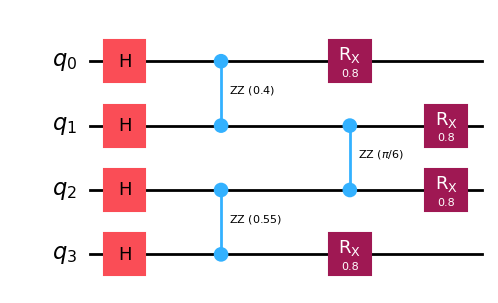

In [10]:
def make_worked_circuit(theta=np.pi/6):
    circuit = QuantumCircuit(4)
    circuit.h(range(4))
    circuit.rzz(0.4, 0, 1)
    circuit.rzz(0.55, 2, 3)
    circuit.rzz(theta, 1, 2)
    circuit.rx(0.8, range(4))
    return circuit

theta = np.pi/6
qc = make_worked_circuit(theta)
target = SparsePauliOp.from_list([("IZZI", 1.0)])
labels = ["A","A","B","B"]
instance = Instance("workbook-one-rzz", qc, target, max_width=2,
                    shots=12000, hardware=HardwareProfile(),
                    seed=SEED, family="teaching",
                    metadata={"purpose": "one crossing RZZ gate"})
show_circuit(qc, "Original circuit; target Z1 Z2")

### Ejercicio 2 · Identificar las puertas que cruzan entre fragmentos

Implementé `student_crossing_indices(circuit, partition_labels)` para encontrar las puertas de dos qubits cuyos participantes pertenecen a fragmentos distintos.

La puerta **RZZ(0.4)** entre `q0` y `q1` se queda en el fragmento A, y **RZZ(0.55)** entre `q2` y `q3` se queda en B. La puerta **RZZ(π/6)** entre `q1` y `q2` cruza la división; en este circuito corresponde al índice 6. Si todos los qubits pertenecieran a A, la función devolvería una lista vacía porque no existiría ninguna interacción entre fragmentos.

Recorro `circuit.data` y comparo las etiquetas de los qubits en cada puerta de dos qubits, en lugar de escribir directamente el índice 6. Así la función sirve para otros circuitos con el mismo tipo de instrucciones.

In [11]:

def student_crossing_indices(circuit, partition_labels):
    # Guardo los indices de las puertas que conectan fragmentos distintos.
    cruces = []

    # Recorro todas las instrucciones del circuito.
    for indice, instruccion in enumerate(circuit.data):

        # Solo reviso las operaciones que utilizan dos qubits.
        if len(instruccion.qubits) == 2:

            # Obtengo los dos qubits que participan en la puerta.
            q1, q2 = instruccion.qubits

            # Busco la posicion de cada qubit en el circuito.
            pos1 = circuit.find_bit(q1).index
            pos2 = circuit.find_bit(q2).index

            # Compruebo si pertenecen a fragmentos diferentes.
            if partition_labels[pos1] != partition_labels[pos2]:
                cruces.append(indice)

    # Devuelvo los indices de las puertas que cruzan.
    return cruces


ex2_answer = student_crossing_indices(qc, labels)
if ex2_answer is None:
    report("E2", "Pending: identify boundary-crossing instructions")
else:
    assert ex2_answer == [6]
    assert student_crossing_indices(qc, ["A"]*4) == []
    assert student_crossing_indices(qc, ["A","B","A","B"]) == [4,5,6]
    report("E2", "Calculation checks passed: review your partition explanation")

E2: Calculation checks passed: review your partition explanation


### Comprobación: borrar una puerta cambia el problema

La siguiente celda calcula el valor ideal del circuito completo y lo compara con el valor obtenido **si quitamos la puerta que cruza los fragmentos**.

Son valores de diagnóstico que permiten comprobar el efecto de esa interacción. No se usan para decidir ni ejecutar el plan: el planificador solo puede apoyarse en sus entradas y las mediciones disponibles. Una descomposición correcta debe conservar el efecto de la puerta que estamos cortando.

In [12]:
diagnostic_reference = float(
    Statevector.from_instruction(qc).expectation_value(target).real)
deleted = qc.copy()
del deleted.data[6]
deleted_reference = float(
    Statevector.from_instruction(deleted).expectation_value(target).real)
display(pd.Series({"original ideal answer": diagnostic_reference,
                   "answer after deleting the gate": deleted_reference}))
# Estos valores de diagnóstico no se pasan a plan() ni a execute().

,0
original ideal answer,0.443207
answer after deleting the gate,0.000000


**Otra comprobación clásica.** Este circuito es lo suficientemente sencillo para calcular su valor ideal mediante una fórmula. Sea $\alpha=0.4$ y $\delta=0.55$ los ángulos de las dos RZZ internas, $\theta=\pi/6$ el ángulo de la RZZ que cruza la división y $\beta=0.8$ el ángulo final de RX:

$$\langle Z_1Z_2\rangle=\sin\theta\,\cos\beta\,\sin\beta\,(\cos\alpha+\cos\delta)\approx0.4432073161.$$

Si $\theta=0$, la interacción de frontera se elimina y el resultado ideal es cero. Esta fórmula sirve para **verificar** el experimento, pero no es la estimación que debe producir el planificador. El reto consiste en obtenerla a partir de los experimentos más pequeños. La derivación está en [la guía original](planner-prompt.md#what-this-example-establishes).

## 3. El complemento de Qiskit genera las recetas locales · 15 minutos

La biblioteca **`qiskit-addon-cutting`** incluye herramientas para descomponer puertas, generar experimentos y reconstruir valores esperados. En este ejemplo descomponemos una puerta RZZ para poder trabajar con los fragmentos por separado.

Una **receta** indica qué operación se hace en A, cuál en B y qué coeficiente con signo corresponde a ese par. Las expresiones $\mathcal A_r$ y $\mathcal B_r$ representan acciones locales; $\mathcal A_r\otimes\mathcal B_r$ significa que cada acción opera sobre su fragmento. No hay que confundirlo con el producto externo $|u\rangle\langle v|$, que construye un operador a partir de vectores.

Las acciones que aparecen son: **I** (identidad), **Z** (puerta Pauli Z), **S** (matriz diagonal con entradas 1 e i), **Sdg** (inversa de S) y **Mz** (medir Z a mitad del circuito y guardar su signo para el resultado final). La medición con signo es un recurso del cálculo; no equivale por sí sola a un canal físico ordinario que preserve la traza.

In [13]:
# Worked example: inspect the actual addon basis in its RAW order.
basis = QPDBasis.from_instruction(RZZGate(theta))
operation_names = {"qpd_measure": "Mz", "sdg": "Sdg", "s": "S", "z": "Z"}
def local_recipe(operations):
    return " then ".join(operation_names.get(op.name, op.name)
                         for op in operations) or "I"

raw_recipe_table = pd.DataFrame([
    {"raw index (0-based)": r, "A boundary": local_recipe(pair[0]),
     "B boundary": local_recipe(pair[1]), "coefficient": float(weight)}
    for r, (weight, pair) in enumerate(zip(basis.coeffs, basis.maps))
])
display(raw_recipe_table)
print("gamma =", basis.kappa, "; gamma squared =", basis.overhead)

,raw index (0-based),A boundary,B boundary,coefficient
0,0,I,I,0.933013
1,1,Z,Z,0.066987
2,2,Mz,S,0.250000
3,3,Mz,Sdg,-0.250000
4,4,S,Mz,0.250000
5,5,Sdg,Mz,-0.250000


gamma = 2.0 ; gamma squared = 4.0


### ¿Por qué aparecen seis recetas?

Para una puerta $U=RZZ(\theta)$, Qiskit utiliza

$$U=a(I\otimes I)-ib(Z\otimes Z),\qquad a=\cos(\theta/2),\quad b=\sin(\theta/2).$$

Aunque en esta expresión solo aparecen dos términos, para describir la acción de la puerta sobre el estado hay que calcular $U\rho U^\dagger$. Al expandirlo aparecen términos cuadrados y también **términos cruzados** asociados a la interferencia. Escoger al azar solamente I/I o Z/Z no bastaría.

La descomposición utiliza I/I y Z/Z para los términos cuadrados, con coeficientes $a^2$ y $b^2$. Los cuatro términos restantes involucran mediciones y fases con coeficientes $+ab,-ab,+ab,-ab$. Como $ab=\sin(\theta)/2$, el orden original de coeficientes es:

$$[\cos^2(\theta/2),\ \sin^2(\theta/2),\ +\sin(\theta)/2,\ -\sin(\theta)/2,\ +\sin(\theta)/2,\ -\sin(\theta)/2].$$

Para $\theta=\pi/6$, los seis son distintos de cero. Cada receta usa experimentos locales tanto en A como en B. Los shots se asignan más adelante. Otros ángulos pueden anular algunos coeficientes, y otras descomposiciones pueden necesitar una cantidad distinta de recetas.

**Álgebra opcional:** $\mathcal M(X)=P_0XP_0-P_1XP_1=(ZX+XZ)/2$ y $\mathcal D(X)=SXS^\dagger-S^\dagger XS=-i(ZX-XZ)$. La combinación $\mathcal M\otimes\mathcal D+\mathcal D\otimes\mathcal M$ produce $-i[(Z\otimes Z),\rho]$ y explica los cuatro signos mixtos.

### Ejercicio 3 · Obtener coeficientes y una medida de costo

Implementé `student_rzz_coefficients(angle)` para calcular los seis coeficientes de la descomposición RZZ en el orden solicitado. También implementé `student_gamma_squared(coefficients)`, que suma los valores absolutos y eleva el resultado al cuadrado.

Cuando el ángulo es cero, el primer coeficiente vale 1 y los demás valen 0. La puerta RZZ se comporta como la identidad y $\gamma^2=1$.

Si el ángulo cambia de signo, los dos primeros coeficientes no cambian porque están elevados al cuadrado; los cuatro términos que dependen del seno cambian de signo. Sin embargo, $\gamma^2$ conserva el mismo valor porque se calculan valores absolutos.

Para el ángulo $\pi/6$, $\gamma^2=4$. Eso **no** significa que haya cuatro experimentos: es un indicador del sobrecosto estadístico de reconstrucción. En este caso tenemos seis recetas y dos fragmentos, es decir, doce configuraciones experimentales.

In [14]:
def student_rzz_coefficients(angle):
    # Calculo la mitad del angulo de la puerta RZZ.
    mitad = angle / 2

    # Calculo los dos primeros coeficientes.
    c1 = np.cos(mitad) ** 2
    c2 = np.sin(mitad) ** 2

    # Calculo los cuatro coeficientes restantes.
    # Tienen el mismo valor absoluto, pero cambian de signo.
    mezcla = np.sin(angle) / 2

    # Devuelvo los seis coeficientes en el orden solicitado.
    return np.array([
        c1, c2,
        mezcla, -mezcla,
        mezcla, -mezcla
    ])


def student_gamma_squared(coefficients):
    # Obtengo el valor absoluto de cada coeficiente.
    valores_absolutos = np.abs(coefficients)

    # Sumo todos los valores para calcular gamma.
    gamma = np.sum(valores_absolutos)

    # Devuelvo gamma elevado al cuadrado.
    return gamma ** 2


ex3_answer = student_rzz_coefficients(theta)
if ex3_answer is None or student_gamma_squared(basis.coeffs) is None:
    report("E3", "Pending: implement coefficients and coefficient norm")
else:
    for test_angle in [0.0, theta, -0.7, np.pi/2]:
        expected = QPDBasis.from_instruction(RZZGate(test_angle))
        assert np.allclose(student_rzz_coefficients(test_angle), expected.coeffs)
        assert np.isclose(student_gamma_squared(expected.coeffs), expected.overhead)
    report("E3", "Calculation checks passed: review the overhead interpretation")

E3: Calculation checks passed: review the overhead interpretation


## 4. Generar los experimentos físicos · 10 minutos

Ahora usamos directamente el complemento de Qiskit. La función **`partition_problem`**, al recibir las etiquetas de los fragmentos, detecta las puertas que cruzan y crea plantillas locales. En algunos tutoriales primero se usa `cut_gates` y después se particiona; aquí el programa combina ambos pasos.

`generate_cutting_experiments` sustituye las partes cortadas por las recetas adecuadas y agrega las mediciones.

Con **`num_samples=np.inf`** pedimos enumerar de forma exacta los coeficientes QPD. Esto **no** significa que hagamos infinitas mediciones físicas: los shots reales serán finitos y se asignarán después.

El orden en que devuelve las recetas puede ser distinto del orden original. En este ejemplo el coeficiente pequeño de Z/Z aparece al final. Por eso hay que mantener siempre cada coeficiente junto con sus circuitos correspondientes.

In [15]:
problem = partition_problem(qc, partition_labels=labels,
                            observables=PauliList(["IZZI"]))
raw_experiments, generated_coefficients = generate_cutting_experiments(
    problem.subcircuits, problem.subobservables, num_samples=np.inf)
coefficients = np.array([float(c) for c, _ in generated_coefficients])

def boundary_action(circuit):
    actions = [operation_names[i.operation.name] for i in circuit.data
               if i.operation.name in {"s", "sdg", "z"}]
    qpd_bits = {bit for register in circuit.cregs
                if register.name == "qpd_measurements" for bit in register}
    if any(i.operation.name == "measure" and
           any(bit in qpd_bits for bit in i.clbits) for i in circuit.data):
        actions.insert(0, "Mz")
    return " then ".join(actions) or "I"

generated_table = pd.DataFrame([
    {"recipe (1-based)": r+1,
     "A boundary": boundary_action(raw_experiments["A"][r]),
     "B boundary": boundary_action(raw_experiments["B"][r]),
     "coefficient": coefficients[r]}
    for r in range(len(coefficients))
])
display(generated_table)
assert len(coefficients) == 6
assert sum(len(v) for v in raw_experiments.values()) == 12

,recipe (1-based),A boundary,B boundary,coefficient
0,1,I,I,0.933013
1,2,Mz,S,0.250000
2,3,Mz,Sdg,-0.250000
3,4,S,Mz,0.250000
4,5,Sdg,Mz,-0.250000
5,6,Z,Z,0.066987


Recipe 2: A: original q0 and q1


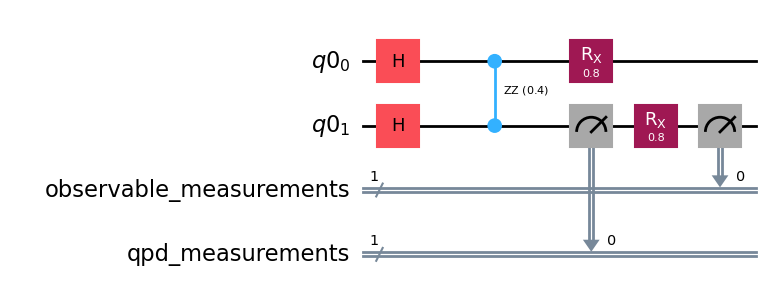

Recipe 2: B: original q2 and q3


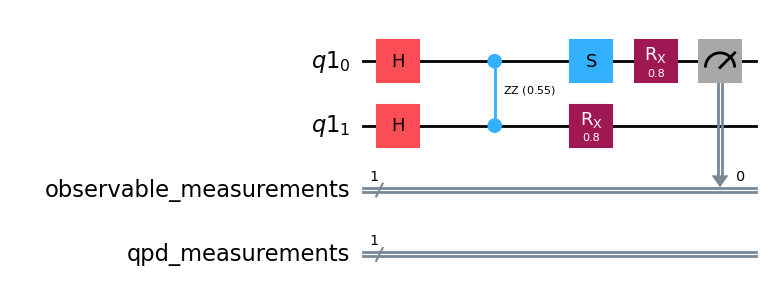

Recipe 2 coefficient: 0.24999999999999997


In [16]:
show_circuit(raw_experiments["A"][1], "Recipe 2: A: original q0 and q1")
show_circuit(raw_experiments["B"][1], "Recipe 2: B: original q2 and q3")
print("Recipe 2 coefficient:", coefficients[1])
assert generated_table.iloc[1]["A boundary"] == "Mz"
assert generated_table.iloc[1]["B boundary"] == "S"
assert np.isclose(coefficients[1], 0.25)

### Un mismo shot puede contener dos mediciones importantes

En la receta 2, el fragmento A mide un qubit de la frontera a mitad del circuito y obtiene un bit $m$. Luego continúa con las rotaciones RX y mide un bit final $a$. El puntaje de ese shot es

$$(-1)^m(-1)^a=(-1)^{m+a}.$$

**Primero multiplico los signos dentro de cada shot y después saco el promedio.** No es correcto, en general, multiplicar los promedios individuales porque ambas mediciones pueden estar correlacionadas. Tampoco se descartan resultados por tener signo negativo ni se hace postselección.

En esta receta, B no tiene medición de corte: su bit final $b$ aporta $(-1)^b$. Como los datos locales de A y B se obtienen de manera independiente, después sí podemos multiplicar los **promedios de los puntajes** de ambos fragmentos durante la reconstrucción.

In [17]:
# Contraejemplo: aquí los dos bits coinciden en cada shot.
toy_cut_bits = np.array([0,0,1,1])
toy_final_bits = np.array([0,0,1,1])
cut_signs = 1 - 2 * toy_cut_bits
final_signs = 1 - 2 * toy_final_bits
print("Mean of within-shot products:", np.mean(cut_signs * final_signs))
print("Product of separate means:", cut_signs.mean() * final_signs.mean())

Mean of within-shot products: 1.0
Product of separate means: 0.0


### Ejercicio 4 · Conservar el signo de la medición

Implementé `student_signed_scores(cut_bits, final_bits)` para obtener un resultado por shot, multiplicando el signo de la medición intermedia por el de la medición final. Primero convierto cada bit 0 en +1 y cada bit 1 en −1.

Un puntaje negativo no significa que el circuito sea incorrecto o físicamente imposible; simplemente indica que los dos bits de ese shot son diferentes. Tampoco debemos eliminar los registros cuyo bit de corte vale 1, porque aportan información a la reconstrucción. Si los descartamos o ignoramos el signo, cambia el resultado estimado.

Es importante multiplicar los signos dentro de cada shot **antes** de promediar: en general, el promedio de productos no coincide con el producto de los promedios.

In [18]:
def student_signed_scores(cut_bits, final_bits):
    # Convierto los resultados de las mediciones intermedias
    # en signos: 0 corresponde a +1 y 1 corresponde a -1.
    signo_corte = 1 - 2 * np.asarray(cut_bits, dtype=int)

    # Hago lo mismo con las mediciones finales.
    signo_final = 1 - 2 * np.asarray(final_bits, dtype=int)

    # Multiplico los signos de cada shot para obtener
    # su resultado, sin calcular todavia el promedio.
    return signo_corte * signo_final


ex4_m = np.array([0,1,0,1,1,0])
ex4_a = np.array([0,0,1,1,0,0])
ex4_answer = student_signed_scores(ex4_m, ex4_a)
if ex4_answer is None:
    report("E4", "Pending: include the mid-circuit sign")
else:
    assert np.array_equal(ex4_answer, [1,-1,-1,1,-1,1])
    assert np.array_equal(student_signed_scores(toy_cut_bits, toy_final_bits), np.ones(4))
    print("Average signed score:", np.mean(ex4_answer))
    report("E4", "Calculation checks passed: review the meaning of a negative score")

Average signed score: 0.0
E4: Calculation checks passed: review the meaning of a negative score


## 5. Comprobar la reconstrucción antes de tomar muestras · 10 minutos

**`ExactSampler`** calcula las probabilidades exactas de los posibles resultados, incluyendo ramas creadas por mediciones intermedias. Esto permite revisar el álgebra en un ejemplo pequeño, antes de utilizar un número finito de shots en la sección 7.

Como aquí solo pedimos un observable de Pauli, los bits relevantes del observable y los signos del corte intervienen en una misma paridad. En ejemplos más generales habría que seleccionar únicamente los bits del observable que realmente importan. El motor incluido en el proyecto ya contempla esos casos.

In [19]:
exact_results = {label: ExactSampler().run(circuits).result()
                 for label, circuits in raw_experiments.items()}
exact_means = {}
for label, sampled in exact_results.items():
    exact_means[label] = np.array([
        sum((1 if int(outcome).bit_count() % 2 == 0 else -1) * probability
            for outcome, probability in distribution.items())
        for distribution in sampled.quasi_dists
    ], dtype=float)
exact_official = float(reconstruct_expectation_values(
    exact_results, generated_coefficients, problem.subobservables)[0])
exact_table = generated_table.copy()
exact_table["A exact signed mean"] = exact_means["A"]
exact_table["B exact signed mean"] = exact_means["B"]
display(exact_table)
print("Addon reconstruction:", exact_official)
assert np.isclose(exact_official, diagnostic_reference, atol=1e-12)

,recipe (1-based),A boundary,B boundary,coefficient,A exact signed mean,B exact signed mean
0,1,I,I,0.933013,0.000000,0.000000
1,2,Mz,S,0.250000,0.696707,0.611564
2,3,Mz,Sdg,-0.250000,0.696707,-0.611564
3,4,S,Mz,0.250000,0.660729,0.696707
4,5,Sdg,Mz,-0.250000,-0.660729,0.696707
5,6,Z,Z,0.066987,0.000000,0.000000


Addon reconstruction: 0.44320731614817743


Una barra encima de una letra, como $\bar a_r$, representa un promedio. La reconstrucción se calcula mediante:

$$\hat E=\sum_{r=1}^{6}c_r\bar a_r\bar b_r.$$

Para cada fila multiplico el promedio de A, el promedio de B y el coeficiente correspondiente; después sumo los aportes de las seis recetas. Los coeficientes se conocen antes de medir, mientras que los promedios se obtienen de los experimentos locales, incluyendo sus signos.

En este ejemplo la preparación se puede separar entre A y B y el observable objetivo es un producto de observables Z locales. Por eso funciona esta forma de multiplicar promedios. La suma con signo recupera el **valor esperado pedido**, pero ninguna receta individual reconstruye el estado completo de cuatro qubits.

### Ejercicio 5 · Reconstruir sin usar la función auxiliar

Implementé `student_reconstruct(coefficients, a_means, b_means)` para calcular el aporte de cada receta y sumar los seis aportes al final. La función devuelve tanto los aportes individuales como la estimación total.

Debo mantener cada coeficiente asociado a sus resultados de A y B. Si cambio el orden de los promedios de B pero no el de A, mezclo experimentos que no corresponden a la misma receta y la reconstrucción deja de ser correcta.

Al multiplicar promedios medidos de los dos fragmentos se supone independencia estadística entre las estimaciones de A y B para cada receta. Esa independencia permite usar su producto como estimador de la contribución correspondiente. También es importante conservar los signos de los coeficientes y de las mediciones.

In [20]:
def student_reconstruct(coefficients, a_means, b_means):
    # Convierto los datos en arreglos de NumPy para poder
    # realizar las operaciones entre los valores de cada receta.
    coeficientes = np.asarray(coefficients, dtype=float)
    promedios_a = np.asarray(a_means, dtype=float)
    promedios_b = np.asarray(b_means, dtype=float)

    # Multiplico el coeficiente de cada receta por los
    # promedios correspondientes de los fragmentos A y B.
    aportes = coeficientes * promedios_a * promedios_b

    # Sumo todos los aportes para reconstruir el resultado.
    estimacion = np.sum(aportes)

    # Devuelvo los aportes individuales y el resultado final.
    return aportes, float(estimacion)


ex5_answer = student_reconstruct(coefficients, exact_means["A"], exact_means["B"])
if ex5_answer is None:
    report("E5", "Pending: calculate all row contributions")
else:
    ex5_parts, ex5_estimate = ex5_answer
    assert np.allclose(ex5_parts, coefficients * exact_means["A"] * exact_means["B"])
    assert np.isclose(ex5_estimate, exact_official)
    _, probe = student_reconstruct([0.5,-0.2], [0.8,0.4], [-0.5,0.3])
    assert np.isclose(probe, -0.224)
    report("E5", "Calculation checks passed: review row matching and independence")

E5: Calculation checks passed: review row matching and independence


## 6. Preparar el plan y contabilizar los shots físicos · 10 minutos

El paquete agrega herramientas para compilar según el hardware disponible, revisar el máximo de qubits, distribuir shots, ejecutar y estimar la incertidumbre. La opción **`structured_cut`** usa bloques consecutivos de dos qubits; es una estrategia didáctica y no es lo mismo que una búsqueda automática de cortes.

El plan se construye **antes de medir**, así que no puede conocer la respuesta ideal de diagnóstico. Si una ejecución directa no cabe en el límite de qubits del hardware, debe aparecer como **no disponible**, sin inventar un error numérico.

In [21]:
try:
    plan(instance, "direct")
except InfeasiblePlan as error:
    print("Expected direct-width rejection:", error)
else:
    raise AssertionError("Four-qubit direct execution should not fit width two.")

prepared = plan(instance, "structured_cut", "coefficient")
summary = prepared.summary()
display(pd.Series({key: summary[key] for key in [
    "decision", "gate_cuts", "experiments", "maximum_experiment_width",
    "physical_shots", "maximum_qpd_overhead",
]}))
assert summary["experiments"] == 12
assert summary["physical_shots"] == 12000
assert summary["maximum_experiment_width"] <= 2

Expected direct-width rejection: direct circuit exceeds maximum experiment width


,0
decision,cut
gate_cuts,1
experiments,12
maximum_experiment_width,2
physical_shots,12000
maximum_qpd_overhead,4.0


**Dos fragmentos, seis pares de recetas y doce configuraciones experimentales.** Cada configuración es un circuito concreto que se ejecuta varias veces según sus shots asignados. Las configuraciones podrían ejecutarse una detrás de otra en un mismo dispositivo compatible.

La distribución por coeficientes reserva primero dos shots para cada experimento y reparte los restantes usando la magnitud de los coeficientes, con redondeos. Es una heurística fija; **no garantiza la varianza mínima**. Tanto los shots de A como los de B se descuentan del mismo presupuesto total.

En el registro del motor, la partición numérica **0 significa A** y **1 significa B** en este ejemplo.

,experiment index,recipe (1-based),fragment,physical width,physical shots
0,0,1,0,2,2795
1,1,2,0,2,751
2,2,3,0,2,751
3,3,4,0,2,751
4,4,5,0,2,751
5,5,6,0,2,203
6,6,1,1,2,2795
7,7,2,1,2,750
8,8,3,1,2,750
9,9,4,1,2,750


,physical shots
fragment,
0,6002
1,5998


Whole-request total: 12000
A compiled physical experiment: gates/layout may change


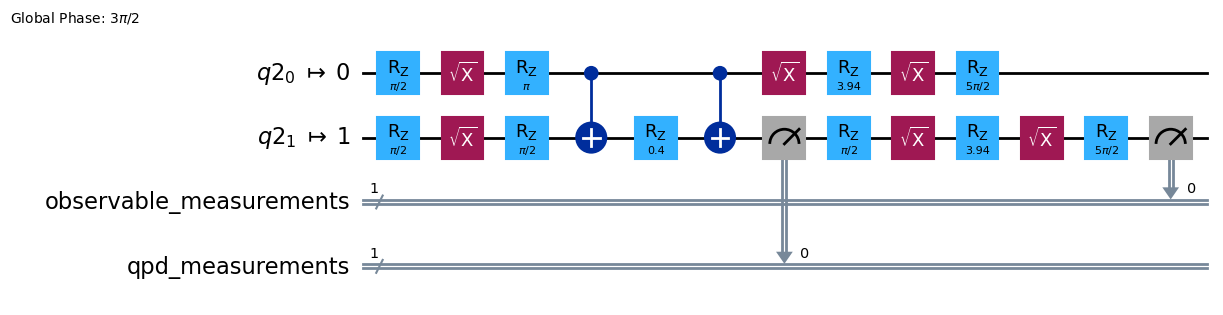

In [22]:
ledger = pd.DataFrame([
    {"experiment index": i, "recipe (1-based)": e.qpd_term+1,
     "fragment": str(e.partition), "physical width": e.circuit.num_qubits,
     "physical shots": e.shots}
    for i, e in enumerate(prepared.experiments)
])
display(ledger)
display(ledger.groupby("fragment")[["physical shots"]].sum())
print("Whole-request total:", int(ledger["physical shots"].sum()))
show_circuit(prepared.experiments[1].circuit,
             "A compiled physical experiment: gates/layout may change")

### Ejercicio 6 · Distribuir todo el presupuesto sin duplicarlo

Implementé `student_equal_allocation(budget, experiment_count)` para distribuir un presupuesto entero de shots entre configuraciones, con al menos dos shots por experimento. Para repartir el sobrante utilizo `divmod` y asigno las mediciones adicionales desde los índices menores. Si no alcanza el presupuesto, la función genera `ValueError`.

En el ejemplo hay doce configuraciones y un presupuesto total de 12 000 shots. Si asignara **12 000 shots a cada una**, en realidad gastaría 144 000, lo cual no sería una comparación justa frente a una ejecución directa de 12 000 shots.

Repartir los shots por igual tampoco garantiza la menor incertidumbre: algunas recetas aportan más que otras según sus coeficientes. Una distribución que los tenga en cuenta puede ayudar, aunque su precisión final también depende de las variaciones de cada experimento.

In [23]:
def student_equal_allocation(budget, experiment_count):
    # Compruebo que exista al menos una configuracion.
    if experiment_count <= 0:
        raise ValueError("La cantidad de experimentos debe ser positiva.")

    # Cada configuracion necesita como minimo dos shots.
    # Si el presupuesto no alcanza, genero un error.
    if budget < 2 * experiment_count:
        raise ValueError("No hay suficientes shots para todos los experimentos.")

    # Divido el presupuesto para obtener la cantidad base
    # de shots y los que sobran.
    cantidad_base, sobrantes = divmod(budget, experiment_count)

    # Asigno la misma cantidad inicial a todos.
    distribucion = [cantidad_base] * experiment_count

    # Reparto los shots sobrantes entre los primeros experimentos.
    for indice in range(sobrantes):
        distribucion[indice] += 1

    # Devuelvo la lista con la cantidad de shots por experimento.
    return distribucion


ex6_answer = student_equal_allocation(12000, 12)
if ex6_answer is None:
    report("E6", "Pending: allocate a shared budget")
else:
    assert ex6_answer == [1000]*12
    assert student_equal_allocation(25, 12) == [3]+[2]*11
    try:
        student_equal_allocation(23, 12)
    except ValueError:
        pass
    else:
        raise AssertionError("Insufficient budgets must be rejected.")
    report("E6", "Calculation checks passed: review fair budget accounting")

E6: Calculation checks passed: review fair budget accounting


## 7. Ejecutar las muestras · 10 minutos

Aer ejecuta los shots físicos que asignamos. El motor genera semillas aleatorias distintas y reproducibles para cada experimento. Usar la misma semilla en lotes separados podría reiniciar la misma secuencia aleatoria: que un resultado sea reproducible no implica automáticamente que los datos sean independientes.

El motor comprueba que su reconstrucción mediante productos con signo coincide con la reconstrucción del complemento de Qiskit para los mismos registros. Esa coincidencia verifica la **aritmética**, pero no demuestra por sí sola que tengamos precisión suficiente o intervalos de incertidumbre bien calibrados.

In [24]:
result = execute(instance, prepared, seed=SEED, confidence=0.95)
measured_means = np.array([row["mean"] for row in result["experiments"]])
measured_parts = np.array([
    coefficient * np.prod(measured_means[indices])
    for coefficient, indices in prepared.products
])
manual_estimate = prepared.constant + measured_parts.sum()
assert np.isclose(manual_estimate, result["estimate"])
assert result["qiskit_reconstruction_agrees"]
assert result["physical_shots"] == instance.shots
print("Finite-shot estimate:", result["estimate"])
print("Diagnostic ideal reference:", diagnostic_reference)
print("Physical shots:", result["physical_shots"])
output_directory = ROOT / "results" / "01-cut-and-reconstruct"
write_json(output_directory / "result.json", {"ideal_reference": diagnostic_reference, **result})
write_json(output_directory / "signed-ledger.json", ledger.to_dict("records"))

Finite-shot estimate: 0.4301322186601428
Diagnostic ideal reference: 0.4432073161481776
Physical shots: 12000


In [ ]:
contribution_rows = []
for r, (coefficient, indices) in enumerate(prepared.products):
    contribution_rows.append({
        "recipe": r+1, "coefficient": coefficient,
        "A mean": measured_means[indices[0]], "B mean": measured_means[indices[1]],
        "contribution": measured_parts[r],
    })
display(pd.DataFrame(contribution_rows))
print("Sum of six contributions:", measured_parts.sum())

### Revisar con calma una de las filas

La **receta 2** tiene coeficiente **+0.25**. El promedio de A incluye tanto el signo de la medición intermedia como el del observable final. El promedio de B incluye el signo de su medición final. Para calcular el aporte de esta receta multiplico esos dos promedios por 0.25. El valor final es la suma de los aportes de las seis recetas.

A partir de un promedio registrado también puedo recuperar cuántos puntajes combinados fueron positivos o negativos:

$$n_+=(n+n\bar x)/2,\qquad n_-=(n-n\bar x)/2.$$

Estos conteos corresponden a los puntajes ±1 ya combinados. **No** permiten reconstruir los dos bits individuales de A.

In [25]:
row2_weight, row2_indices = prepared.products[1]
row2_counts = []
for name, index in zip(["A","B"], row2_indices):
    n = prepared.experiments[index].shots
    average = measured_means[index]
    positive = int(round(n*(1+average)/2))
    negative = n-positive
    assert np.isclose((positive-negative)/n, average)
    row2_counts.append({"fragment": name, "positive scores": positive,
                        "negative scores": negative, "shots": n, "mean": average})
display(pd.DataFrame(row2_counts))
print("Row 2 contribution:", row2_weight*np.prod(measured_means[row2_indices]))

,fragment,positive scores,negative scores,shots,mean
0,A,620,131,751,0.651132
1,B,594,156,750,0.584000


Row 2 contribution: 0.0950652463382157


## 8. ¿Qué representa la incertidumbre? · 10 minutos

El error estándar mostrado es una **aproximación basada en valores estimados**. Para variables independientes, la identidad de la varianza de un producto incluye un término que ciertas aproximaciones de primer orden omiten:

$$\operatorname{Var}(XY)=\mu_X^2v_Y+\mu_Y^2v_X+v_Xv_Y.$$

La identidad es exacta si usamos los momentos verdaderos de variables independientes. Al sustituir momentos estimados, eso no garantiza que los intervalos tengan la cobertura esperada.

El intervalo conservador usa límites de Hoeffding para puntajes acotados, una cota por unión entre los experimentos y operaciones de intervalos para los productos con signo. La asignación de shots está fija y los shots de un mismo experimento deben ser independientes y tener la misma distribución. También se necesita independencia entre los datos de los fragmentos para la propiedad de insesgadez del producto.

El intervalo cuantifica la **incertidumbre por muestreo del valor reconstruido con ruido**, no garantiza que el hardware esté libre de sesgo respecto al circuito ideal. En este ejemplo las tasas de error sintético son cero, así que ambas cantidades coinciden. Un procedimiento de confianza del 95 % se refiere a su cobertura en muchas repeticiones; no significa que este intervalo concreto tenga un 95 % de probabilidad posterior de contener el valor verdadero.

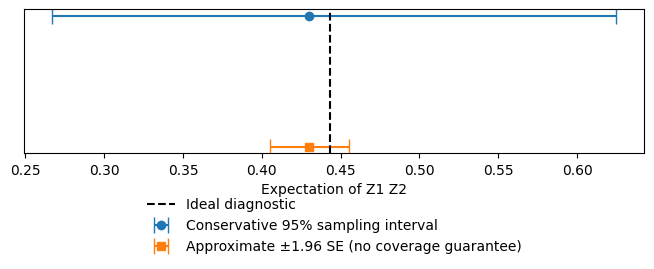

Conservative interval: [0.267103510176732, 0.6246456837623029]


In [26]:
lower, upper = result["sampling_interval"]
estimate = result["estimate"]
approx_se = result["sampling_standard_error_approx"]
fig, ax = plt.subplots(figsize=(8,3))
ax.errorbar(estimate, 1, xerr=[[estimate-lower],[upper-estimate]],
            fmt="o", capsize=6, label="Conservative 95% sampling interval")
ax.errorbar(estimate, 0, xerr=1.96*approx_se, fmt="s", capsize=6,
            label="Approximate ±1.96 SE (no coverage guarantee)")
ax.axvline(diagnostic_reference, color="black", linestyle="--", label="Ideal diagnostic")
ax.set_yticks([])
ax.set_xlabel("Expectation of Z1 Z2")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.22), frameon=False)
fig.subplots_adjust(bottom=0.4)
display(fig)
plt.close(fig)
print("Conservative interval:", [lower, upper])

### Ejercicio 7 · Interpretar las barras de error

**1. Si un intervalo es estrecho, pero no contiene el valor ideal, ¿qué pudo pasar?**

Esto puede ocurrir por un error sistemático, como ruido del circuito o un sesgo de medición, o simplemente por la variación del muestreo. No podemos identificar la causa con una sola ejecución. Tener un intervalo pequeño no garantiza que la estimación esté cerca del valor correcto.

**2. Si el intervalo contiene el valor ideal, ¿qué podemos concluir?**

Podemos decir que la referencia es compatible con el intervalo observado y el procedimiento empleado para estimar la incertidumbre. Pero eso no demuestra que el método sea exacto ni que todos los intervalos futuros vayan a contener el valor ideal.

**3. ¿Qué cambia al aumentar los shots?**

Más shots suelen reducir el error estadístico de los promedios, pero no arreglan por sí solos errores sistemáticos ni una fórmula incorrecta. Además, en circuit cutting seguimos teniendo el costo de ejecutar varios experimentos para reconstruir el resultado; el indicador de sobrecosto $\gamma^2$ no desaparece por aumentar el presupuesto.

Estas respuestas se refieren al significado general de los intervalos. En este ejemplo se utilizan simulaciones y los resultados guardados del cuaderno.

In [27]:
ex7_answers = {

    "narrow_but_misses_ideal":
        "Aunque el intervalo sea pequeño, eso no garantiza que "
        "contenga el resultado ideal. Puede existir un error "
        "sistematico causado por el ruido del circuito, o una "
        "diferencia debida a las muestras obtenidas. Con una sola "
        "ejecucion no podemos asegurar cual fue la causa.",

    "one_interval_contains_reference":
        "Que el intervalo contenga el valor ideal significa que "
        "el resultado es compatible con esa referencia, tomando "
        "en cuenta la incertidumbre calculada. Sin embargo, esto "
        "no demuestra que el metodo sea exacto ni que siempre "
        "vaya a producir resultados correctos.",

    "more_shots":
        "Al aumentar los shots podemos reducir el error estadistico "
        "porque tenemos mas mediciones para calcular los promedios. "
        "Sin embargo, el ruido sistematico o los errores del modelo "
        "pueden mantenerse. Ademas, el sobrecosto de reconstruccion "
        "sigue existiendo, por lo que necesitamos repartir las "
        "mediciones entre los diferentes experimentos."
}

if all(isinstance(v,str) and v.strip() for v in ex7_answers.values()):
    report("E7", "Responses supplied: self/peer review required, not auto-graded")
else:
    report("E7", "Pending: write all three uncertainty explanations")

E7: Responses supplied: self/peer review required, not auto-graded


## 9. Comparar métodos bajo condiciones equivalentes · 15–20 minutos

Primero permitimos hasta **cuatro qubits físicos** para que la ejecución directa sea posible. Conservamos el mismo circuito, observable, perfil de ruido y un presupuesto de **12 000 shots por solicitud**. El método directo y cada método de corte utilizan presupuestos separados. Una repetición es otra solicitud con sus propios 12 000 shots.

Comparamos tres alternativas: ejecución directa, corte con distribución uniforme y corte con distribución proporcional a los coeficientes. Cuatro repeticiones permiten observar algo de variación, pero una comparación general necesitaría más circuitos y más repeticiones. Si un método excede el límite de qubits, debe quedar marcado como no disponible.

In [28]:
comparable_instance = replace(instance, max_width=4,
                              instance_id="workbook-one-width4-comparison")
comparison_plans = {
    "direct": plan(comparable_instance, "direct", "equal"),
    "cut_equal": plan(comparable_instance, "structured_cut", "equal"),
    "cut_coefficient": plan(comparable_instance, "structured_cut", "coefficient"),
}
display(pd.DataFrame([
    {"method": name, "shots per request": candidate.summary()["physical_shots"],
     "max physical width": candidate.summary()["maximum_experiment_width"],
     "logical fragment widths": candidate.metadata["logical_fragment_widths"],
     "experiment settings": candidate.summary()["experiments"]}
    for name, candidate in comparison_plans.items()
]))
# Preparar el plan no consume shots físicos.

,method,shots per request,max physical width,logical fragment widths,experiment settings
0,direct,12000,4,[4],1
1,cut_equal,12000,4,[2],12
2,cut_coefficient,12000,4,[2],12


### Ejercicio 8 · Hacer y explicar una comparación justa

Implementé `student_comparison(base, plans, seeds)` para realizar cuatro repeticiones de cada uno de los tres métodos: `direct`, `cut_equal` y `cut_coefficient`. En cada ejecución guardé el método, el número de repetición, la estimación y la cantidad de shots físicos. Utilicé semillas diferentes y reproducibles en las doce ejecuciones.

Cada solicitud tuvo un presupuesto de **12 000 shots**; por lo tanto, el estudio completo utilizó **144 000 shots físicos**. El valor ideal solo se usó después de ejecutar los métodos, para calcular sus errores, y no se entregó al planificador.

**Hipótesis:** esperaba que el método directo tuviera un error menor porque no necesita dividir y reconstruir el circuito. También consideré que repartir shots según los coeficientes podría mejorar la precisión respecto al reparto uniforme, aunque eso no estaba garantizado.

**Resultados obtenidos en Colab (cuatro repeticiones por método):**

| Método | RMSE |
|---|---:|
| `direct` | 0.003105 |
| `cut_equal` | 0.013143 |
| `cut_coefficient` | 0.026051 |

En estas ejecuciones, **el método directo tuvo el RMSE más bajo**. Entre las dos estrategias de corte, el reparto uniforme resultó mejor que el basado en coeficientes, contrario a mi hipótesis inicial. Esto puede depender del circuito, las varianzas de las recetas y el número limitado de repeticiones.

**Límites de la comparación:** solo estudié un circuito y un observable, e hice cuatro repeticiones por método. Por eso no puedo asegurar que un método sea siempre mejor que otro. Además, la ejecución directa requiere cuatro qubits físicos, mientras que el corte permite trabajar con fragmentos de dos qubits, por lo que también importa la capacidad del hardware disponible.

**Qué probaría después:** repetiría el experimento con más semillas y con diferentes ángulos RZZ, para comprobar si las diferencias de RMSE se mantienen. También sería útil comparar el rendimiento con ruido de hardware real.

In [29]:
def student_comparison(base, plans, seeds):
    # Creo una lista para guardar los resultados de cada prueba.
    resultados = []

    # Preparo semillas diferentes para cada metodo y repeticion.
    # Esto permite repetir el experimento con los mismos resultados.
    lista_semillas = list(seeds)
    generador = np.random.SeedSequence(lista_semillas)
    semillas_hijas = generador.spawn(len(plans) * len(lista_semillas))

    posicion = 0

    # Recorro los tres metodos que vamos a comparar.
    for metodo, plan_preparado in plans.items():

        # Ejecuto cuatro repeticiones de cada metodo.
        for repeticion, _ in enumerate(lista_semillas):

            # Obtengo una semilla diferente para esta ejecucion.
            semilla = int(
                semillas_hijas[posicion].generate_state(1)[0]
            )
            posicion += 1

            # Ejecuto el circuito con el metodo correspondiente.
            resultado = execute(
                base,
                plan_preparado,
                seed=semilla
            )

            # Guardo el metodo, la repeticion, la estimacion
            # obtenida y la cantidad de shots utilizados.
            resultados.append({
                "method": metodo,
                "repetition": repeticion,
                "estimate": float(resultado["estimate"]),
                "physical_shots": int(resultado["physical_shots"])
            })

    # Organizo todos los resultados en una tabla.
    return pd.DataFrame(
        resultados,
        columns=[
            "method",
            "repetition",
            "estimate",
            "physical_shots"
        ]
    )


study_seeds = [SEED+100+i for i in range(4)]
ex8_frame = student_comparison(comparable_instance, comparison_plans, study_seeds)
if ex8_frame is None:
    report("E8", "Pending: execute a matched comparison and discuss limitations")
else:
    assert {"method","repetition","estimate","physical_shots"} <= set(ex8_frame.columns)
    assert len(ex8_frame) == 12
    assert set(ex8_frame["method"]) == set(comparison_plans)
    assert not ex8_frame.duplicated(["method","repetition"]).any()
    assert set(ex8_frame["repetition"]) == set(range(4))
    assert (ex8_frame.groupby("method").size() == 4).all()
    assert np.isfinite(ex8_frame["estimate"]).all()
    assert (ex8_frame["physical_shots"] == comparable_instance.shots).all()
    scored = ex8_frame.assign(squared_error=(
        ex8_frame["estimate"]-diagnostic_reference)**2)
    display(scored.groupby("method").agg(
        mean_squared_error=("squared_error","mean"),
        repetitions=("repetition","count"),
    ).assign(RMSE=lambda frame: np.sqrt(frame["mean_squared_error"])))
    print("Study-wide physical shots:", int(ex8_frame["physical_shots"].sum()))
    report("E8", "Study completed: interpretation still needs scientific review")

,mean_squared_error,repetitions,RMSE
method,,,
cut_coefficient,0.000679,4,0.026051
cut_equal,0.000173,4,0.013143
direct,0.000010,4,0.003105


Study-wide physical shots: 144000
E8: Study completed: interpretation still needs scientific review


## Diferencias que debo mantener claras en la entrega

- Un **fragmento** es un grupo local de qubits y operaciones; una **receta** indica qué acciones aplicar en cada fragmento; una **configuración experimental** es un circuito específico; un **shot** es una ejecución de ese circuito.
- Los coeficientes negativos y los signos de las mediciones se usan en los cálculos clásicos. **No son probabilidades negativas**.
- Enumerar exactamente los coeficientes QPD **no** elimina la incertidumbre debida a una cantidad finita de mediciones.
- Un planificador puede decidir cortes, distribución en hardware, preparación previa, presupuesto y descomposiciones alternativas válidas. Cambiar signos o quitar filas sin justificación puede romper la equivalencia exacta.
- $\gamma^2$ indica una posible amplificación del costo estadístico, **no** es una aceleración medida, el número de configuraciones ni la varianza exacta de esta estimación.

Material de consulta: [tutorial oficial para reducir el ancho del circuito](https://qiskit.github.io/qiskit-addon-cutting/tutorials/01_gate_cutting_to_reduce_circuit_width.html), [guía de coeficientes exactos](https://qiskit.github.io/qiskit-addon-cutting/how-tos/how_to_generate_exact_sampling_coefficients.html) y [descomposición implementada](https://qiskit.github.io/qiskit-addon-cutting/_modules/qiskit_addon_cutting/qpd/decompositions.html).

**Detalle técnico del material original:** los signos usados aquí coinciden con la implementación del complemento versión 0.10.0 y comprobaciones matriciales independientes. Una tabla introductoria de la documentación muestra signos mixtos opuestos con la misma convención declarada. Por eso, al comparar tablas conviene revisar la implementación y las convenciones.

In [30]:
display(pd.DataFrame({"exercise": list(progress), "status": list(progress.values())}))
pending = [name for name,status in progress.items() if status.startswith("Pending")]
print("Still pending:", ", ".join(pending) if pending else "No blank exercises detected.")
print("Written reasoning and scientific claims still need your review.")

,exercise,status
0,E1,Calculation checks passed: review your written...
1,E2,Calculation checks passed: review your partiti...
2,E3,Calculation checks passed: review the overhead...
3,E4,Calculation checks passed: review the meaning ...
4,E5,Calculation checks passed: review row matching...
5,E6,Calculation checks passed: review fair budget ...
6,E7,"Responses supplied: self/peer review required,..."
7,E8,Study completed: interpretation still needs sc...


Still pending: No blank exercises detected.
Written reasoning and scientific claims still need your review.


## Resumen de la entrega

El cuaderno conserva las soluciones, la tabla de recetas, las comprobaciones de cálculo, el registro de shots y la comparación de RMSE de los tres métodos. Los resultados corresponden a esta ejecución en Google Colab, no a una garantía de comportamiento para cualquier circuito.

Una idea que considero fundamental es que cortar un circuito no consiste en borrar las puertas que conectan los fragmentos: necesitamos reconstruir su efecto mediante recetas locales, coeficientes con signo y mediciones. Así podemos reducir el ancho de cada experimento, aunque eso tenga un costo estadístico adicional.

Consulta complementaria: [tutorial oficial de Qiskit para reducir el ancho de un circuito mediante cortes](https://qiskit.github.io/qiskit-addon-cutting/tutorials/01_gate_cutting_to_reduce_circuit_width.html).